# Chapter 7 · The Itô integral: interactive demos

Companion to Chapter 7 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/07-ito-integral.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

All integrals are computed as left-point (Itô) sums $\sum_j H_{t_j}(W_{t_{j+1}}-W_{t_j})$ on a uniform grid.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from ieor222.brownian import brownian_paths
from ieor222.itointegral import (ito_integral, lambda_sum, midpoint_sum, quadratic_variation,
                                 simulate, time_integral, wdw_limit)
from ieor222.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

use_style()
GREEN = PALETTE[2]

## 1. Where to evaluate the integrand: $\int_0^T W\,\mathrm{d}W$

For $\lambda\in[0,1]$, the sum $S_\lambda=\sum_j\big((1-\lambda)W_{t_j}+\lambda W_{t_{j+1}}\big)(W_{t_{j+1}}-W_{t_j})$
equals $\tfrac12W_T^2+(\lambda-\tfrac12)\sum_j(W_{t_{j+1}}-W_{t_j})^2$ on every path, so it converges to
$\tfrac12W_T^2+(\lambda-\tfrac12)T$ (Proposition 7.11). Only $\lambda=0$, the left point, gives the Itô integral
$\tfrac12(W_T^2-T)$.

Left panel: one path, the sums for your $\lambda$ (black) and for the left point, the midpoint and the right point
(faint), as the number $n$ of intervals grows. Right panel: the average over many paths of the running sum
$S_\lambda(t)$, against its exact mean $\lambda t$. Only $\lambda=0$ stays at zero: only the left point gives a martingale.

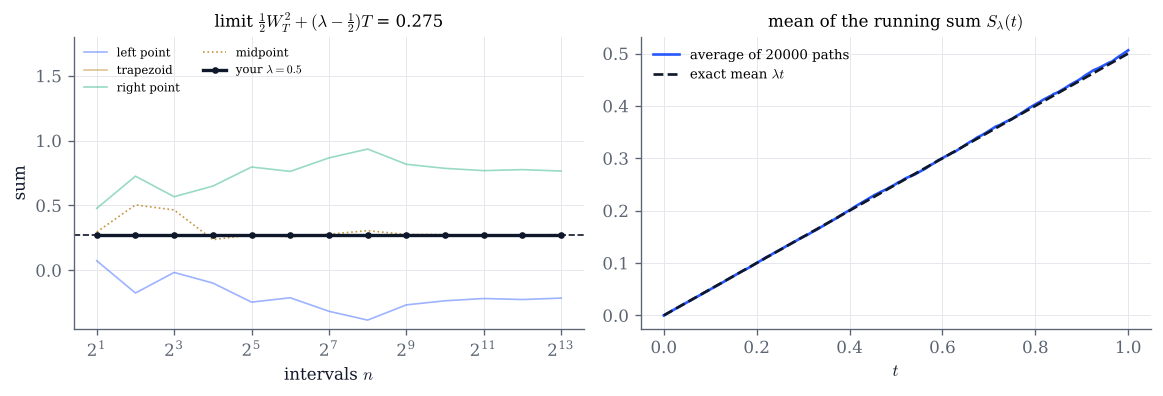

In [2]:
def evaluation_point(lam=0.5, T=1.0, seed=0):
    K = 14
    _, W = brownian_paths(T=T, n_steps=2**K, n_paths=1, seed=seed)
    w = W[0]
    ks = np.arange(1, K)
    n = 2**ks
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    for l, color, label in ((0.0, COBALT, "left point"), (0.5, GOLD, "trapezoid"), (1.0, GREEN, "right point")):
        ax.plot(n, [lambda_sum(w, l, every=2**(K - k)) for k in ks], color=color, lw=1, alpha=0.45, label=label)
    ax.plot(n, [midpoint_sum(w, every=2**(K - k)) for k in ks], color=GOLD, lw=1, ls=":", alpha=0.8, label="midpoint")
    ax.plot(n, [lambda_sum(w, lam, every=2**(K - k)) for k in ks], color=INK, lw=2, marker="o", ms=3,
            label=f"your $\\lambda={lam:g}$")
    ax.axhline(wdw_limit(w[-1], T, lam), color=INK, ls="--", lw=1)
    ax.set(xscale="log", xlabel="intervals $n$", ylabel="sum",
           title=f"limit $\\frac{{1}}{{2}}W_T^2+(\\lambda-\\frac{{1}}{{2}})T$ = {wdw_limit(w[-1], T, lam):.3f}")
    ax.set_xscale("log", base=2)
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi + 0.55 * (hi - lo))
    ax.legend(fontsize=7, ncol=2, loc="upper left")

    t, Wp = brownian_paths(T=T, n_steps=200, n_paths=20_000, seed=seed + 1)
    dW = np.diff(Wp, axis=1)
    running = np.concatenate([np.zeros((len(Wp), 1)),
                              np.cumsum(((1 - lam) * Wp[:, :-1] + lam * Wp[:, 1:]) * dW, axis=1)], axis=1)
    ax2.plot(t, running.mean(0), color=COBALT, label="average of 20000 paths")
    ax2.plot(t, lam * t, color=INK, ls="--", label="exact mean $\\lambda t$")
    ax2.set(xlabel="$t$", title="mean of the running sum $S_\\lambda(t)$")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

evaluation_point()

In [3]:
# Explore: move the evaluation point. lambda = 0 is Ito, 1/2 is Stratonovich, 1 is the right point.
interact(evaluation_point,
         lam=FloatSlider(value=0.5, min=0.0, max=1.0, step=0.05, continuous_update=False, description="λ"),
         T=FloatSlider(value=1.0, min=0.25, max=4.0, step=0.25, continuous_update=False, description="T"),
         seed=IntSlider(value=0, min=0, max=100, continuous_update=False, description="seed"));

## 2. The Itô isometry, and when the integral is Gaussian

For $H\in\mathbb H^2$, $\mathbb E\big[(\int_0^TH\,\mathrm{d}W)^2\big]=\mathbb E\int_0^TH_t^2\,\mathrm{d}t$ (Theorem 7.7).
Below, both sides are estimated on the same simulated paths, for an integrand of your choice. The histogram compares
$\int_0^TH\,\mathrm{d}W$ with the normal density of the same variance: for a deterministic integrand the integral is
Gaussian (Proposition 7.10); for a random one it need not be.

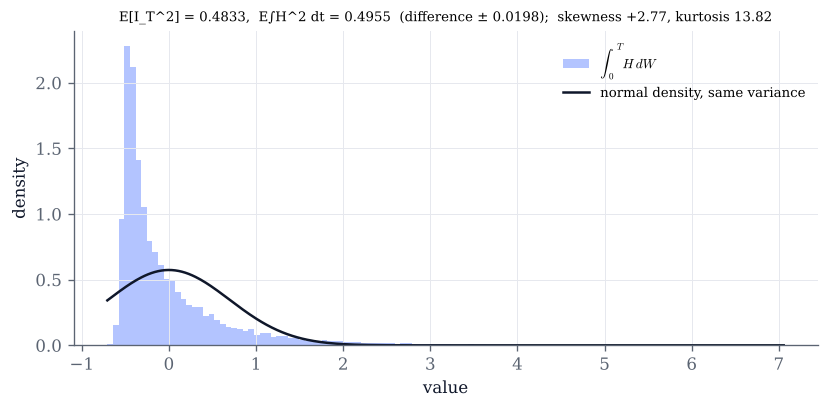

In [4]:
INTEGRANDS = {
    "W_t (random)": lambda t, W: W,
    "W_t^3 (random)": lambda t, W: W**3,
    "cos(W_t) (random, bounded)": lambda t, W: np.cos(W),
    "exp(-t) (deterministic)": lambda t, W: np.exp(-t) + 0 * W,
    "sin(2 pi t) (deterministic)": lambda t, W: np.sin(2 * np.pi * t) + 0 * W,
}

def isometry(integrand="W_t (random)", T=1.0, n_steps=200, n_paths=20_000, seed=2):
    t, W, H, I = simulate(INTEGRANDS[integrand], T=T, n_steps=n_steps, n_paths=n_paths, seed=seed)
    x = I[:, -1]
    lhs, rhs = x**2, time_integral(H**2, t)[:, -1]
    se = (lhs - rhs).std(ddof=1) / np.sqrt(n_paths)
    z = (x - x.mean()) / x.std()
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.hist(x, bins=120, density=True, color=COBALT, alpha=0.35, label="$\\int_0^T H\\,dW$")
    grid = np.linspace(x.min(), x.max(), 400)
    v = x.var()
    ax.plot(grid, np.exp(-grid**2 / (2 * v)) / np.sqrt(2 * np.pi * v), color=INK, lw=1.5,
            label="normal density, same variance")
    ax.set(xlabel="value", ylabel="density",
           title=(f"E[I_T^2] = {lhs.mean():.4f},  E∫H^2 dt = {rhs.mean():.4f}  (difference ± {1.96*se:.4f});  "
                  f"skewness {np.mean(z**3):+.2f}, kurtosis {np.mean(z**4):.2f}"))
    ax.title.set_fontsize(8)
    ax.legend(fontsize=8)
    plt.show()

isometry()

In [5]:
# Explore: compare a deterministic integrand (Gaussian, kurtosis 3) with random ones.
interact(isometry,
         integrand=Dropdown(options=list(INTEGRANDS), value="W_t (random)", description="H"),
         T=FloatSlider(value=1.0, min=0.25, max=3.0, step=0.25, continuous_update=False, description="T"),
         n_steps=IntSlider(value=200, min=10, max=1000, step=10, continuous_update=False, description="steps"),
         n_paths=IntSlider(value=20_000, min=2_000, max=100_000, step=2_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=2, min=0, max=100, continuous_update=False, description="seed"));

## 3. The quadratic variation of an integral path

Along one path, the sum of squared increments of $I=\int H\,\mathrm{d}W$ over a grid of $n$ intervals approaches
$[I,I]_t=\int_0^tH_s^2\,\mathrm{d}s$ as $n$ grows (Theorem 7.7(vi)). The quadratic variation is computed from one path
and is random; the variance $\mathbb E[I_t^2]=\mathbb E\int_0^tH_s^2\,\mathrm{d}s$ (dashed, estimated from 2000 paths) is its mean.
The integral itself is computed on a fine grid of $2^{14}$ steps.

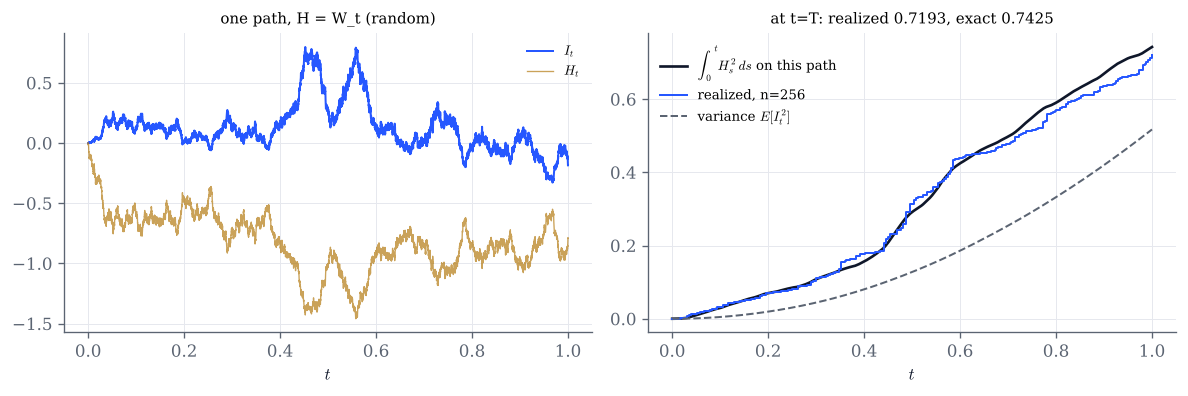

In [6]:
def qv(integrand="W_t (random)", n=256, T=1.0, seed=7):
    K = 14
    t, W, H, I = simulate(INTEGRANDS[integrand], T=T, n_steps=2**K, n_paths=1, seed=seed)
    every = max(1, 2**K // n)
    tc = t[::every]
    realized = quadratic_variation(I[0], every=every)
    exact = time_integral(H[0]**2, t)
    tm, Wm, Hm, _ = simulate(INTEGRANDS[integrand], T=T, n_steps=256, n_paths=2000, seed=seed + 1)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(t, I[0], color=COBALT, lw=1.2, label="$I_t$")
    ax.plot(t, H[0], color=GOLD, lw=0.8, alpha=0.7, label="$H_t$")
    ax.set(xlabel="$t$", title=f"one path, H = {integrand}")
    ax.title.set_fontsize(9)
    ax.legend(fontsize=8)
    ax2.plot(t, exact, color=INK, lw=1.6, label="$\\int_0^t H_s^2\\,ds$ on this path")
    ax2.step(tc, realized, where="post", color=COBALT, lw=1.2, label=f"realized, n={len(tc) - 1}")
    ax2.plot(tm, time_integral(Hm**2, tm).mean(0), color=GREY, ls="--", lw=1.2, label="variance $E[I_t^2]$")
    ax2.set(xlabel="$t$", title=f"at t=T: realized {realized[-1]:.4f}, exact {exact[-1]:.4f}")
    ax2.title.set_fontsize(9)
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

qv()

In [7]:
# Explore: refine the grid and watch the realized quadratic variation settle on the path's own int H^2 ds.
interact(qv,
         integrand=Dropdown(options=list(INTEGRANDS), value="W_t (random)", description="H"),
         n=IntSlider(value=256, min=2, max=4096, step=2, continuous_update=False, description="n"),
         T=FloatSlider(value=1.0, min=0.25, max=3.0, step=0.25, continuous_update=False, description="T"),
         seed=IntSlider(value=7, min=0, max=100, continuous_update=False, description="seed"));

## Things to try

- In section 1, set $\lambda=1$. The average of the running sum grows like $t$: a trader who knows each period's closing
  price before choosing her position gains on average. How does the slope compare with $[W,W]_t=t$?
- In section 1, the trapezoid sum ($\lambda=\tfrac12$) equals $\tfrac12W_T^2$ for every $n$, not just in the limit. Why?
- In section 2, take a deterministic integrand and check that the kurtosis is close to 3. Then take $W_t^3$: how far
  from Gaussian is the integral, and how many paths do you need before the two sides of the isometry agree?
- In section 3, for a deterministic integrand the realized quadratic variation approaches the dashed variance curve;
  for a random one it does not. Which statement of the notes explains this?